In [2]:
import numpy as np
import scipy
import pandas as pd
import matplotlib.pyplot as plt

print("Ready to analyze cockroach data!")

Ready to analyze cockroach data!


# **Part 1: Importing and Exploring the Data**

## Step 1: Inspecting our File Format

In [3]:
# Importing libraries
from pathlib import Path
from scipy.io import whosmat

# Locating the MATLAB file
file_path = Path("../Data/Roach lab day 1 10mV Sin.mat")

# Checking whether Python can find it
print("File found:", file_path.exists())

# Displaying the variables stored inside
if file_path.exists():
    for name, shape, data_type in whosmat(file_path):
        print(name, shape, data_type)

File found: True
data (1, 24000000) double
datastart (2, 30) double
dataend (2, 30) double
titles (2,) char
rangemin (2, 30) double
rangemax (2, 30) double
unittext (1,) char
unittextmap (2, 30) double
blocktimes (1, 30) double
tickrate (1, 30) double
samplerate (2, 30) double
firstsampleoffset (2, 30) double
comtext (0,) char
com (0, 5) double


# Step 2: Inspecting our Recording Information

In [4]:
import numpy as np
from scipy.io import loadmat

# Load the MATLAB file
mat = loadmat(file_path)

# Display channel information
print("Channel names:", mat["titles"])

# Count recording blocks
print("Number of recordings:", mat["datastart"].shape[1])

# Display sampling frequencies
print("Sampling rates (Hz):", np.unique(mat["samplerate"]))

# Calculate recording durations
samples = mat["dataend"] - mat["datastart"] + 1
durations = samples / mat["samplerate"]

print("Recording durations (seconds):",
      np.unique(np.round(durations, 2)))

Channel names: ['Channel 1' 'Channel 2']
Number of recordings: 30
Sampling rates (Hz): [40000.]
Recording durations (seconds): [10.]


# **Part 2: Visualizing the Raw Data**

# Step 1: Visualize one recording

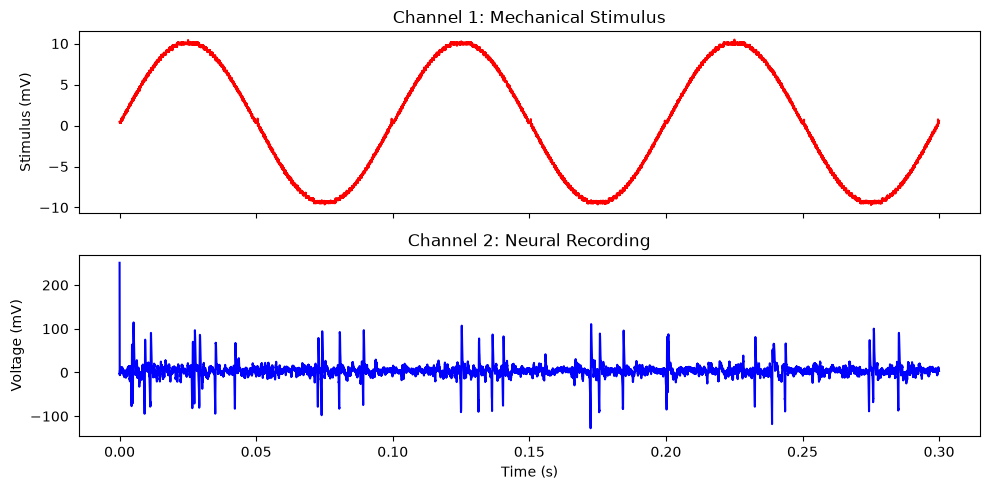

In [5]:
# Select recording block 1
block = 0

# Extract the recorded signals
data = mat["data"].flatten()

def get_channel(channel, block):
    start = int(mat["datastart"][channel, block]) - 1
    end = int(mat["dataend"][channel, block])
    return data[start:end]

stimulus = get_channel(0, block)
neural = get_channel(1, block)

# Create a time axis
fs = 40000
time = np.arange(len(stimulus)) / fs

# Display the first 0.3 seconds
duration = 0.3
n = int(duration * fs)

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

# Channel 1: Mechanical stimulus
ax[0].plot(time[:n], stimulus[:n] * 1000, color="red")
ax[0].set_ylabel("Stimulus (mV)")
ax[0].set_title("Channel 1: Mechanical Stimulus")

# Channel 2: Neural activity
ax[1].plot(time[:n], neural[:n] * 1000, color="blue")
ax[1].set_ylabel("Voltage (mV)")
ax[1].set_xlabel("Time (s)")
ax[1].set_title("Channel 2: Neural Recording")

plt.tight_layout()
plt.savefig("../Figures/Figure2_MechanicalAndNeuralRecording.png", dpi=300)
plt.show()

# **Part 3: Detecting Action Potentials**

## Step 1: Detect Action Potentials in the 10 mV Recording

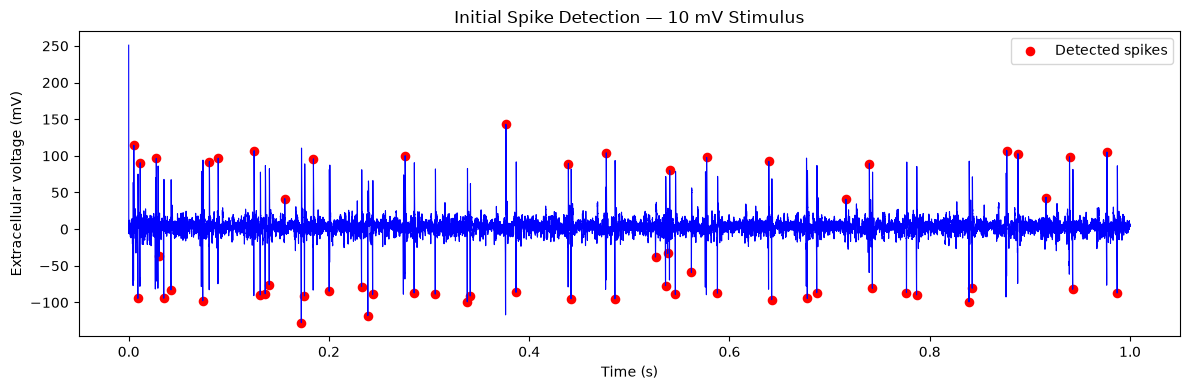

Detection threshold: 35.56 mV
Candidate spikes detected: 59


In [6]:

from scipy.signal import find_peaks

# Select the first 0.3 seconds
duration = 1
n = int(duration * fs)

# Extract neural activity and convert to mV
# Signal: Extracts the neural recording
signal = neural[:n] * 1000
t = np.arange(n) / fs

# Estimate background noise
# baseline: estimates the cenrtal voltage level 
baseline = np.median(signal)
noise = 1.4826 * np.median(np.abs(signal - baseline))

# Set an initial detection threshold
threshold = 5 * noise

# Detect positive and negative spike-like events
spikes, _ = find_peaks(
    np.abs(signal - baseline),
    height=threshold,
    distance=int(0.002 * fs)
)

# Plot neural activity and detected spikes
plt.figure(figsize=(12, 4))

plt.plot(t, signal, color="blue", linewidth=0.8)

plt.scatter(
    t[spikes],
    signal[spikes],
    color="red",
    s=35,
    label="Detected spikes"
)

plt.xlabel("Time (s)")
plt.ylabel("Extracellular voltage (mV)")
plt.title("Initial Spike Detection — 10 mV Stimulus")
plt.legend()
plt.tight_layout()
plt.show()

print("Detection threshold:", round(threshold, 2), "mV")
print("Candidate spikes detected:", len(spikes))

#### Explanation of Peak Finding: 

We can identify likely action potentials by examining three characteristics:
1. Shape: Extracellular action potentials often have a characteristic waveform, with rapid positive and negative voltage deflections.
2. Duration: Action potentials are brief electrical events, typically lasting a few milliseconds or less.
3. Consistency: Spikes recorded from the same neuron should have relatively similar shapes and durations

- The threshold is the minimum electrical signal amplitude that the algorith considers a potential action potential

*Detection threshold = 5 x Estimated noise level*

(This means, if noise is usually around +5mV, we multiply it by 5 and that gives 25mV as a sufficiently large electrical event to be classified as an action potential)

- MAD (Median Absolute Deviation): Measures how much the recorded voltage typically fluctuates around its median. We use it to estimate background noise without being strongly affected by large spikes.

- 1.4826: A statistical correction factor that converts MAD into an estimate of standard deviation, assuming the noise is approximately normally distributed.

## Step 2: Compare Detected Spike Waveforms

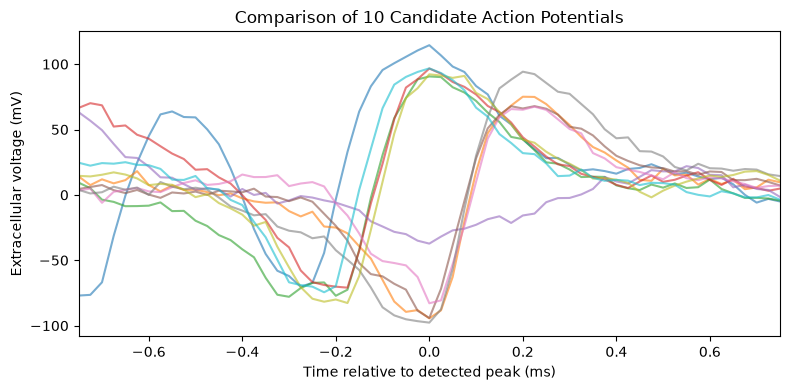

In [7]:
# Extract 2 milliseconds before and after each detected spike
window = int(0.002 * fs)

# Time axis in milliseconds
spike_time = np.arange(-window, window + 1) / fs * 1000

# Select the first 10 spikes that have enough surrounding data
valid_spikes = [
    i for i in spikes
    if i >= window and i + window < len(signal)
]

# Plot 10 spike waveforms
plt.figure(figsize=(8, 4))

for i in valid_spikes[:10]:
    waveform = signal[i-window:i+window+1]
    plt.plot(spike_time, waveform, alpha=0.6)

# Focus on the central spike waveform
plt.xlim(-0.75, 0.75)
plt.xlabel("Time relative to detected peak (ms)")
plt.ylabel("Extracellular voltage (mV)")
plt.title("Comparison of 10 Candidate Action Potentials")

plt.tight_layout()
plt.show()

#### Deciding which Spikes are Actually Action Potentials

What we are looking for:

1. Waveform shape: Do the spikes have similar positive and negative deflections?
2. Spike duration: Do they occur over similar timescales?
3. Consistency: Are the waveforms reasonably similar, or are there clearly different types?



## Step 3: Test negative-peak detection

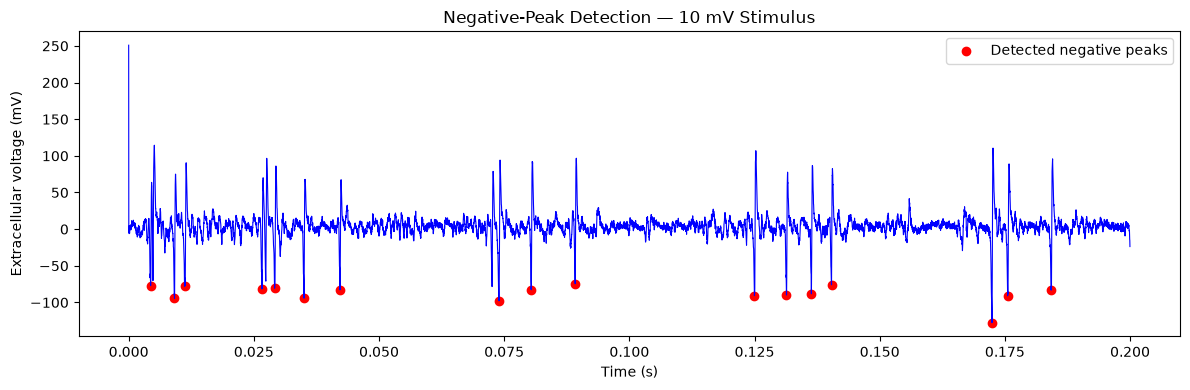

Candidate negative peaks: 55


In [8]:
from scipy.signal import find_peaks

# Detect negative voltage peaks
negative_spikes, _ = find_peaks(
    baseline - signal,
    height=threshold,
    distance=int(0.002 * fs)
)

# Display the first 0.2 seconds
n = int(0.2 * fs)
visible_spikes = negative_spikes[negative_spikes < n]

plt.figure(figsize=(12, 4))

plt.plot(t[:n], signal[:n], color="blue", linewidth=0.8)

plt.scatter(
    t[visible_spikes],
    signal[visible_spikes],
    color="red",
    label="Detected negative peaks"
)

plt.xlabel("Time (s)")
plt.ylabel("Extracellular voltage (mV)")
plt.title("Negative-Peak Detection — 10 mV Stimulus")
plt.legend()
plt.tight_layout()
plt.savefig("../Figures/Figure3_NegativePeakDetection.png", dpi=300)
plt.show()

print("Candidate negative peaks:", len(negative_spikes))

## Step 4: Compare negative-peak waveforms

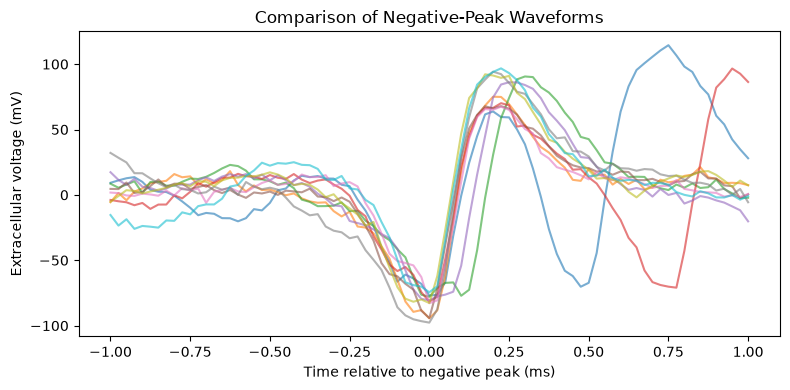

In [9]:
window = int(0.001 * fs)  # 1 ms on either side

spike_time = np.arange(-window, window + 1) / fs * 1000

plt.figure(figsize=(8, 4))

for i in negative_spikes[:10]:
    if i >= window and i + window < len(signal):
        waveform = signal[i-window:i+window+1]
        plt.plot(spike_time, waveform, alpha=0.6)

plt.xlabel("Time relative to negative peak (ms)")
plt.ylabel("Extracellular voltage (mV)")
plt.title("Comparison of Negative-Peak Waveforms")

plt.tight_layout()
plt.savefig("../Figures/Figure3_WaveformComparisons.png", dpi=300)
plt.show()

## Step 5: Analyze the Complete 10-Second Recording

In [10]:
# What does this code do?
# 1. Takes the complete 10-second neural recording.
# 2. Uses our existing 35.56 mV detection threshold.
# 3. Detects large negative peaks.
# 4. Counts the candidate spikes.
# 5. Calculates the preliminary firing rate.

# Use the complete neural recording
full_signal = neural * 1000  # Convert V to mV
full_time = np.arange(len(full_signal)) / fs

# Calculate baseline
full_baseline = np.median(full_signal)

# Detect negative peaks using our initial threshold
full_spikes, _ = find_peaks(
    full_baseline - full_signal,
    height=threshold,
    distance=int(0.002 * fs)
)

# Calculate preliminary firing rate
spike_count = len(full_spikes)
recording_duration = len(full_signal) / fs
firing_rate = spike_count / recording_duration

print("Candidate spikes:", spike_count)
print("Recording duration:", recording_duration, "seconds")
print("Preliminary firing rate:", round(firing_rate, 2), "Hz")

Candidate spikes: 449
Recording duration: 10.0 seconds
Preliminary firing rate: 44.9 Hz


## Step 6: Check Detection in the Middle of the Recording

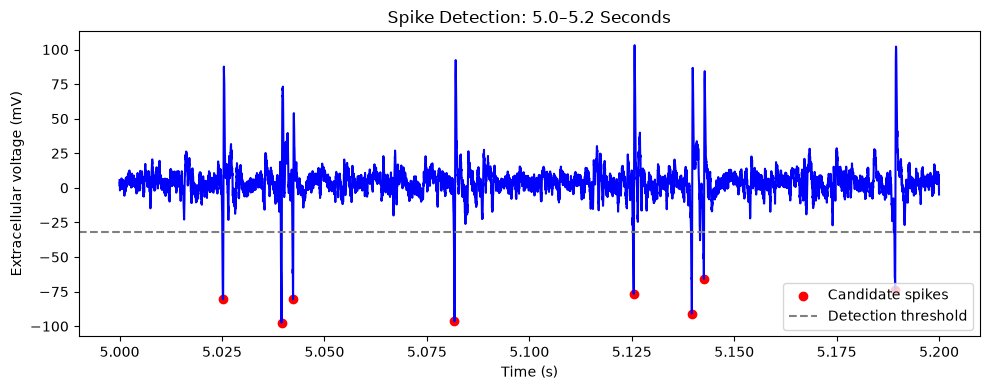

In [11]:
start = 5.0
end = 5.2

# Select this time interval
mask = (full_time >= start) & (full_time < end)

# Select detected spikes within the interval
visible_spikes = full_spikes[
    (full_time[full_spikes] >= start) &
    (full_time[full_spikes] < end)
]

# Plot the recording
plt.figure(figsize=(10, 4))

plt.plot(full_time[mask], full_signal[mask], color="blue")

plt.scatter(
    full_time[visible_spikes],
    full_signal[visible_spikes],
    color="red",
    label="Candidate spikes"
)

plt.axhline(
    full_baseline - threshold,
    color="gray",
    linestyle="--",
    label="Detection threshold"
)

plt.xlabel("Time (s)")
plt.ylabel("Extracellular voltage (mV)")
plt.title("Spike Detection: 5.0–5.2 Seconds")
plt.legend()
plt.tight_layout()
plt.show()

## Step 7: Check Whether our Threshold is Appropriate

In [12]:
# This code will help us check: Does changing our detection threshold slightly produce drastically different spike counts?

# Estimate noise across the complete recording
MAD = np.median(np.abs(full_signal - full_baseline))
noise = 1.4826 * MAD

# Compare three detection thresholds
for multiplier in [4, 5, 6]:

    test_threshold = multiplier * noise

    detected, _ = find_peaks(
        full_baseline - full_signal,
        height=test_threshold,
        distance=int(0.002 * fs)
    )

    rate = len(detected) / recording_duration

    print(f"{multiplier}x noise threshold:")
    print(f"  Threshold: {test_threshold:.2f} mV")
    print(f"  Candidate spikes: {len(detected)}")
    print(f"  Firing rate: {rate:.2f} Hz\n")


4x noise threshold:
  Threshold: 26.13 mV
  Candidate spikes: 603
  Firing rate: 60.30 Hz

5x noise threshold:
  Threshold: 32.66 mV
  Candidate spikes: 471
  Firing rate: 47.10 Hz

6x noise threshold:
  Threshold: 39.20 mV
  Candidate spikes: 434
  Firing rate: 43.40 Hz



# **Part 4: Finding Firing Rates for Different Stimulus Amplitudes**

## Step 1: Calculate Firing Rates for all Recordings

In [13]:

results = []

for block in range(30):

    # Extract both channels
    stimulus = get_channel(0, block) * 1000
    neural = get_channel(1, block) * 1000

    # Estimate background noise
    baseline = np.median(neural)
    MAD = np.median(np.abs(neural - baseline))
    noise = 1.4826 * MAD

    # Detect negative peaks using 6x noise
    threshold = 6 * noise

    spikes, _ = find_peaks(
        baseline - neural,
        height=threshold,
        distance=int(0.002 * fs)
    )

    # Calculate firing rate
    firing_rate = len(spikes) / (len(neural) / fs)

    # Estimate stimulus amplitude from Channel 1
    amplitude = (
        np.percentile(stimulus, 99) -
        np.percentile(stimulus, 1)
    ) / 2

    results.append({
        "Block": block + 1,
        "Amplitude (mV)": round(amplitude, 1),
        "Spike count": len(spikes),
        "Firing rate (Hz)": round(firing_rate, 2)
    })

# Display results
df = pd.DataFrame(results)
print(df.to_string(index=False))

 Block  Amplitude (mV)  Spike count  Firing rate (Hz)
     1        9.800000          434              43.4
     2        9.800000          340              34.0
     3        9.800000          182              18.2
     4        9.800000          175              17.5
     5        9.800000          170              17.0
     6        9.800000          156              15.6
     7       19.799999          709              70.9
     8       19.799999          421              42.1
     9       19.799999          331              33.1
    10       19.799999          248              24.8
    11       19.799999          236              23.6
    12       19.799999          304              30.4
    13       29.799999          660              66.0
    14       29.799999          472              47.2
    15       29.799999          440              44.0
    16       29.799999          337              33.7
    17       29.799999          595              59.5
    18       29.799999      

## Step 2: Calculate Mean Firing Rate for each Stimulus Amplitude

                Mean     SD  N
Stimulus (mV)                 
10             24.28  11.59  6
20             37.48  17.67  6
30             49.47  11.55  6
40             61.27  11.46  6
50             67.62   4.11  6

Regression slope: 1.105 Hz/mV
R²: 0.9870
Exploratory p-value: 0.000635


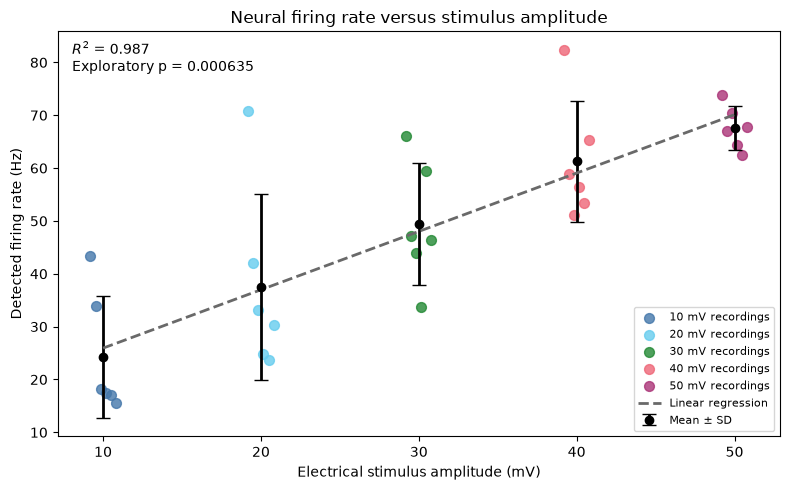

In [28]:
# Group recordings by nominal stimulus amplitude
df["Stimulus (mV)"] = (
    (df["Amplitude (mV)"] / 10).round().astype(int) * 10
)

# Calculate mean, standard deviation, and number of recordings
summary = df.groupby("Stimulus (mV)")["Firing rate (Hz)"].agg(
    Mean="mean",
    SD="std",
    N="count"
)

print(summary.round(2))


# --------------------------------------------------
# LINEAR REGRESSION
# --------------------------------------------------

from scipy.stats import linregress

# Fit regression to the five mean firing rates
x_mean = summary.index.to_numpy(dtype=float)
y_mean = summary["Mean"].to_numpy(dtype=float)

regression = linregress(x_mean, y_mean)

r_squared = regression.rvalue ** 2
p_value = regression.pvalue

print(f"\nRegression slope: {regression.slope:.3f} Hz/mV")
print(f"R²: {r_squared:.4f}")
print(f"Exploratory p-value: {p_value:.6f}")


# --------------------------------------------------
# FIGURE 4A: FIRING RATE VS STIMULUS AMPLITUDE
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

colors = ["#4477AA", "#66CCEE", "#228833", "#EE6677", "#AA3377"]
amplitudes = [10, 20, 30, 40, 50]

# Plot individual recordings
for amplitude, color in zip(amplitudes, colors):

    rates = df.loc[
        df["Stimulus (mV)"] == amplitude,
        "Firing rate (Hz)"
    ].to_numpy()

    x = amplitude + np.linspace(-0.8, 0.8, len(rates))

    ax.scatter(
        x, rates,
        color=color,
        s=50,
        alpha=0.8,
        label=f"{amplitude} mV recordings"
    )

# Plot mean firing rate and standard deviation
ax.errorbar(
    summary.index,
    summary["Mean"],
    yerr=summary["SD"],
    fmt="o",
    color="black",
    linewidth=2,
    capsize=5,
    label="Mean ± SD"
)

# Plot linear regression line
x_line = np.linspace(10, 50, 100)
y_line = regression.intercept + regression.slope * x_line

ax.plot(
    x_line,
    y_line,
    linestyle="--",
    color="dimgray",
    linewidth=2,
    label="Linear regression"
)

# Display regression statistics
ax.text(
    0.02, 0.98,
    f"$R^2$ = {r_squared:.3f}\n"
    f"Exploratory p = {p_value:.4g}",
    transform=ax.transAxes,
    fontsize=10,
    va="top",
    ha="left"
)

ax.set_xlabel("Electrical stimulus amplitude (mV)")
ax.set_ylabel("Detected firing rate (Hz)")
ax.set_title("Neural firing rate versus stimulus amplitude")

ax.set_xticks(amplitudes)
ax.legend(loc="lower right", fontsize=8)

plt.tight_layout()

plt.savefig(
    "../Figures/Figure4_FiringrateVSstimulusamplitude.png",
    dpi=300
)

plt.show()

## Step 3: Examine Firing Rate Across Repeated Recordings

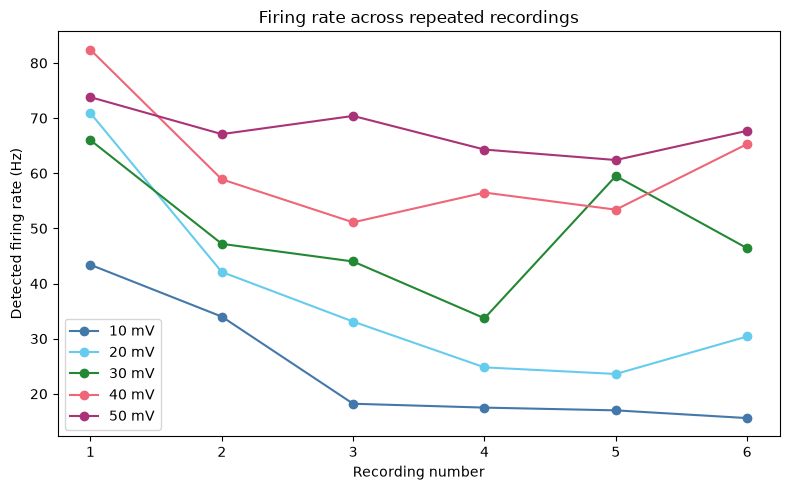

In [15]:
# Number recordings within each stimulus condition
df["Trial"] = df.groupby("Stimulus (mV)").cumcount() + 1

fig, ax = plt.subplots(figsize=(8, 5))

# Plot firing rates for each stimulus amplitude
for amplitude, color in zip(amplitudes, colors):

    subset = df[df["Stimulus (mV)"] == amplitude]

    ax.plot(
        subset["Trial"],
        subset["Firing rate (Hz)"],
        marker="o",
        color=color,
        label=f"{amplitude} mV"
    )

ax.set_xlabel("Recording number")
ax.set_ylabel("Detected firing rate (Hz)")
ax.set_title("Firing rate across repeated recordings")
ax.set_xticks([1, 2, 3, 4, 5, 6])

ax.legend()
plt.tight_layout()

plt.savefig("../Figures/Figure4_FiringRates.png", dpi=300)
plt.show()

# **Part 5: Temporal Analysis of Neuronal Firing**

## Step 1: Extracting Stimulus and Neural Recordings

In [16]:
# Select the first recording (10 mV)
block = 0

# Extract both channels and convert to mV
stim_p4 = get_channel(0, block) * 1000
neural_p4 = get_channel(1, block) * 1000

# Create the time axis
fs_p4 = float(mat["samplerate"][0, block])
time_p4 = np.arange(len(stim_p4)) / fs_p4

# Display recording information
print("Stimulus amplitude: 10 mV")
print("Recording duration:", len(stim_p4) / fs_p4, "seconds")
print("Sampling frequency:", fs_p4, "Hz")

Stimulus amplitude: 10 mV
Recording duration: 10.0 seconds
Sampling frequency: 40000.0 Hz


## Step 2: Detecting Action Potentials and Extracting their Exact Firing Times

In [17]:
# Calculate baseline and background noise
baseline_p4 = np.median(neural_p4)

MAD_p4 = np.median(np.abs(neural_p4 - baseline_p4))

noise_p4 = 1.4826 * MAD_p4

# Use our established 6x noise threshold
threshold_p4 = 6 * noise_p4

# Detect negative peaks
spikes_p4, _ = find_peaks(
    baseline_p4 - neural_p4,
    height=threshold_p4,
    distance=int(0.002 * fs_p4)
)

# Convert spike locations into time (seconds)
spike_times_p4 = spikes_p4 / fs_p4

# Display results
print("Detection threshold:", round(threshold_p4, 2), "mV")
print("Candidate spikes detected:", len(spikes_p4))
print("First 10 spike times (s):")
print(np.round(spike_times_p4[:10], 4))

Detection threshold: 39.2 mV
Candidate spikes detected: 434
First 10 spike times (s):
[0.0044 0.0092 0.0112 0.0266 0.0292 0.035  0.0422 0.074  0.0804 0.0892]


## Step 3: Calculating Stimulus Phase

In [18]:

# Confirm that both channels have matching timing information
assert len(stim_p4) == len(neural_p4)
assert np.allclose(mat["samplerate"][:, block],
                   mat["samplerate"][0, block])

offsets = mat["firstsampleoffset"][:, block]
if not np.isclose(offsets[0], offsets[1]):
    raise ValueError("Channel timing offsets differ. Check alignment.")

# Identify positive peaks of the sinusoidal stimulus
stim_peaks_p4, _ = find_peaks(
    stim_p4,
    prominence=5,
    distance=int(0.08 * fs_p4)
)

# Find the stimulus cycle containing each spike
cycle_p4 = np.searchsorted(stim_peaks_p4, spikes_p4) - 1

# Keep spikes occurring within complete cycles
valid_p4 = (cycle_p4 >= 0) & (cycle_p4 < len(stim_peaks_p4) - 1)

valid_spikes_p4 = spikes_p4[valid_p4]
cycle_p4 = cycle_p4[valid_p4]

# Calculate the phase of each spike (0–360 degrees)
phase_p4 = 360 * (
    (valid_spikes_p4 - stim_peaks_p4[cycle_p4]) /
    (stim_peaks_p4[cycle_p4 + 1] - stim_peaks_p4[cycle_p4])
)

# Display results
print("Complete stimulus cycles:", len(stim_peaks_p4) - 1)
print("Spikes included:", len(phase_p4))
print("First 10 spike phases:", np.round(phase_p4[:10], 1))

Complete stimulus cycles: 99
Spikes included: 428
First 10 spike phases: [  5.6  14.7  35.8  61.6 176.  199.3 230.8 359.6  22.7  40.6]


## Step 4: Spike Phase Distribution

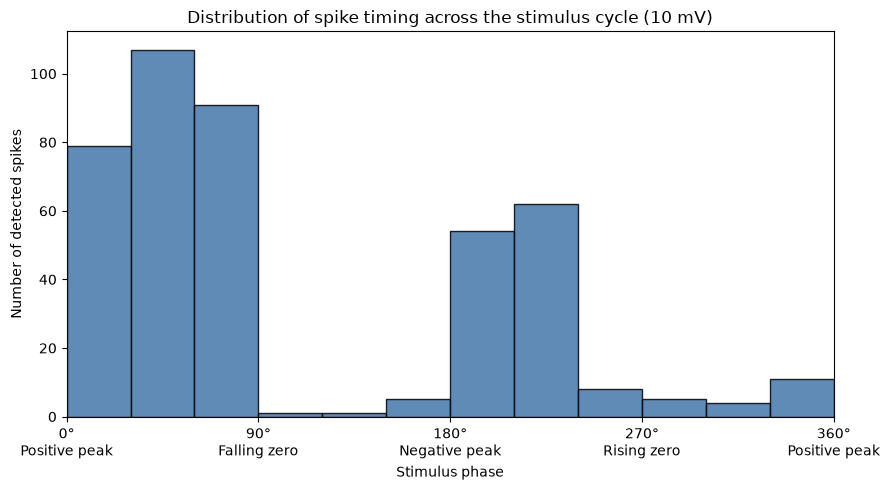

In [19]:


fig, ax = plt.subplots(figsize=(9, 5))

# Divide the stimulus cycle into 12 bins (30° each)
bins_p4 = np.arange(0, 361, 30)

ax.hist(
    phase_p4,
    bins=bins_p4,
    color="#4477AA",
    edgecolor="black",
    alpha=0.85
)

# Label stimulus phases
ax.set_xticks([0, 90, 180, 270, 360])
ax.set_xticklabels([
    "0°\nPositive peak",
    "90°\nFalling zero",
    "180°\nNegative peak",
    "270°\nRising zero",
    "360°\nPositive peak"
])

ax.set_xlabel("Stimulus phase")
ax.set_ylabel("Number of detected spikes")

ax.set_title(
    "Distribution of spike timing across the stimulus cycle (10 mV)"
)

ax.set_xlim(0, 360)

plt.tight_layout()
plt.show()

## Step 5: Analyze all Five Stimulus Amplitudes

In [20]:

# Store spike phases for each stimulus amplitude
phases_by_amplitude = {}

for amplitude in amplitudes:

    all_phases = []
    total_cycles = 0

    # Identify the six recordings for this amplitude
    blocks = df.loc[
        df["Stimulus (mV)"] == amplitude, "Block"
    ]

    for block_number in blocks:

        block_index = int(block_number) - 1

        # Extract both channels
        stim = get_channel(0, block_index) * 1000
        neural = get_channel(1, block_index) * 1000

        fs_block = float(mat["samplerate"][0, block_index])

        # Detect candidate spikes using 6x noise threshold
        baseline = np.median(neural)
        noise = 1.4826 * np.median(np.abs(neural - baseline))

        spikes, _ = find_peaks(
            baseline - neural,
            height=6 * noise,
            distance=int(0.002 * fs_block)
        )

        # Identify positive stimulus peaks
        stim_peaks, _ = find_peaks(
            stim,
            prominence=5,
            distance=int(0.08 * fs_block)
        )

        # Determine stimulus cycle for each spike
        cycle = np.searchsorted(stim_peaks, spikes) - 1

        valid = (cycle >= 0) & (cycle < len(stim_peaks) - 1)

        spikes = spikes[valid]
        cycle = cycle[valid]

        # Calculate spike phases
        phase = 360 * (
            (spikes - stim_peaks[cycle]) /
            (stim_peaks[cycle + 1] - stim_peaks[cycle])
        )

        all_phases.extend(phase)
        total_cycles += len(stim_peaks) - 1

    # Store phases for this amplitude
    phases_by_amplitude[amplitude] = np.array(all_phases)

    print(
        f"{amplitude} mV: "
        f"{len(all_phases)} spikes across "
        f"{total_cycles} complete cycles"
    )

10 mV: 1438 spikes across 594 complete cycles
20 mV: 2230 spikes across 594 complete cycles
30 mV: 2934 spikes across 594 complete cycles
40 mV: 3651 spikes across 594 complete cycles
50 mV: 4022 spikes across 594 complete cycles


## Step 6: Comparing Spike Phase Distributions

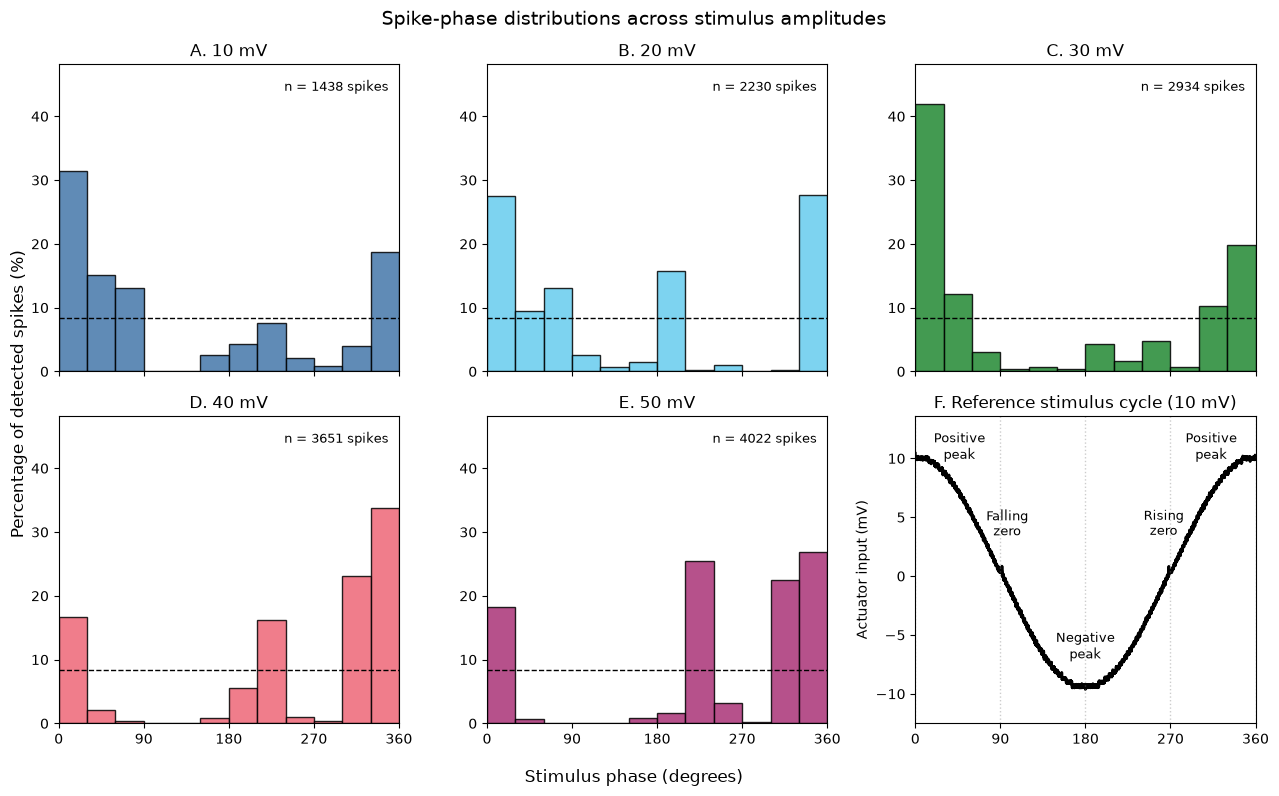

In [21]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(13, 8),
    sharex=True,
    sharey=False
)

axes = axes.flatten()

# Divide the stimulus cycle into 12 bins
bins_p4 = np.arange(0, 361, 30)

# Panel labels
panel_labels = ["A", "B", "C", "D", "E"]

# Calculate the maximum percentage for consistent y-axis scaling
max_percent = 0

for amplitude in amplitudes:
    counts, _ = np.histogram(
        phases_by_amplitude[amplitude],
        bins=bins_p4
    )

    percentages = counts / counts.sum() * 100
    max_percent = max(max_percent, percentages.max())

# Create one histogram per stimulus amplitude
for i, (amplitude, color) in enumerate(zip(amplitudes, colors)):

    ax = axes[i]

    phases = phases_by_amplitude[amplitude]

    # Count spikes in each phase interval
    counts, _ = np.histogram(phases, bins=bins_p4)

    # Convert counts to percentages
    percentages = counts / counts.sum() * 100

    # Plot histogram
    ax.bar(
        bins_p4[:-1],
        percentages,
        width=30,
        align="edge",
        color=color,
        edgecolor="black",
        alpha=0.85
    )

    # Expected percentage for an even distribution
    ax.axhline(
        100 / 12,
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(f"{panel_labels[i]}. {amplitude} mV")

    ax.set_xlim(0, 360)
    ax.set_ylim(0, max_percent * 1.15)

    ax.set_xticks([0, 90, 180, 270, 360])

    # Display number of spikes analyzed
    ax.text(
        0.97, 0.95,
        f"n = {len(phases)} spikes",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9
    )

# --------------------------------------------------
# PANEL F: Reference sinusoidal stimulus cycle
# --------------------------------------------------

ax = axes[5]

# Extract one complete cycle from the recorded 10 mV stimulus
start = stim_peaks_p4[0]
end = stim_peaks_p4[1]

stim_cycle = stim_p4[start:end + 1]

# Convert the cycle into degrees
phase_axis = np.linspace(0, 360, len(stim_cycle))

# Plot the recorded sinusoidal waveform
ax.plot(
    phase_axis,
    stim_cycle,
    color="black",
    linewidth=2
)

# Vertical reference lines at important phases
for degree in [0, 90, 180, 270, 360]:
    ax.axvline(
        degree,
        color="gray",
        linestyle=":",
        alpha=0.4,
        linewidth=1
    )

# Position labels in empty spaces away from the waveform
phase_labels = [
    (0.13, 0.90, "Positive\npeak", "center"),
    (0.27, 0.65, "Falling\nzero", "center"),
    (0.50, 0.25, "Negative\npeak", "center"),
    (0.73, 0.65, "Rising\nzero", "center"),
    (0.87, 0.90, "Positive\npeak", "center")
]

for x, y, label, alignment in phase_labels:
    ax.text(
        x, y,
        label,
        transform=ax.transAxes,
        ha=alignment,
        va="center",
        fontsize=9,
        color="black"
    )

ax.set_title("F. Reference stimulus cycle (10 mV)")
ax.set_ylabel("Actuator input (mV)")
ax.set_xlim(0, 360)
ax.set_ylim(stim_cycle.min() * 1.3, stim_cycle.max() * 1.3)
ax.set_xticks([0, 90, 180, 270, 360])

# Shared labels
fig.supxlabel("Stimulus phase (degrees)", fontsize=12)
fig.supylabel("Percentage of detected spikes (%)", fontsize=12)

fig.suptitle(
    "Spike-phase distributions across stimulus amplitudes",
    fontsize=14
)

plt.tight_layout()

# Save figure
plt.savefig(
    "../Figures/Figure5_SpikePhase_Amplitudes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### How To Interpret the Figure:

X-axis: Stimulus phase (0–360°)
- 0° = positive peak
- 90° = falling zero crossing
- 180° = negative peak
- 270° = rising zero crossing
- 360° = next positive peak

Y-axis: Percentage of detected spikes
- For example, if a bar reaches 25%, it means that 25% of the detected spikes occurred within that 30° interval.

We want to answer three questions:
1. Do spikes cluster at particular phases at every amplitude?
2. Do the preferred firing phases shift as stimulus amplitude increases?
3. Does the spike distribution become more concentrated or more evenly distributed at higher amplitudes?

## Step 7: Validating Phase Locked Spike Detection

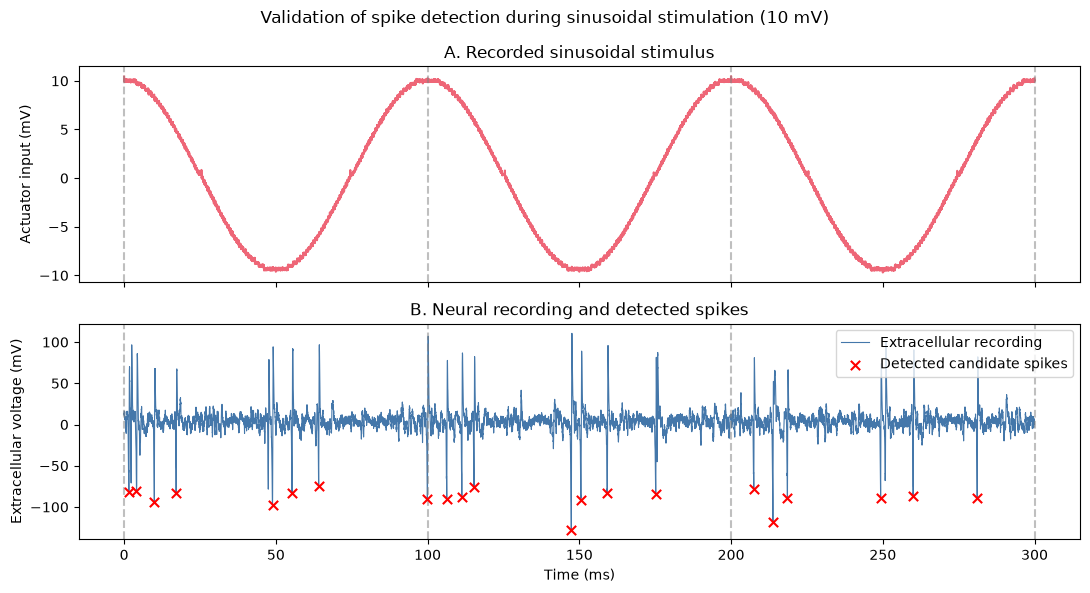

Candidate spikes in displayed interval: 21


In [22]:

# Select three complete stimulus cycles
start_p4 = stim_peaks_p4[0]
end_p4 = stim_peaks_p4[3]

# Create time axis in milliseconds, relative to the first peak
time_window = (
    np.arange(start_p4, end_p4) - start_p4
) / fs_p4 * 1000

# Find detected spikes within this interval
spikes_window = spikes_p4[
    (spikes_p4 >= start_p4) &
    (spikes_p4 < end_p4)
]

# Convert spike times to milliseconds
spike_times_window = (
    spikes_window - start_p4
) / fs_p4 * 1000

# Create two vertically aligned panels
fig, ax = plt.subplots(
    2, 1,
    figsize=(11, 6),
    sharex=True
)

# -----------------------------------------------
# PANEL A: Sinusoidal stimulus
# -----------------------------------------------

ax[0].plot(
    time_window,
    stim_p4[start_p4:end_p4],
    color="#EE6677",
    linewidth=1.5
)

ax[0].set_ylabel("Actuator input (mV)")
ax[0].set_title("A. Recorded sinusoidal stimulus")

# -----------------------------------------------
# PANEL B: Neural recording with detected spikes
# -----------------------------------------------

ax[1].plot(
    time_window,
    neural_p4[start_p4:end_p4],
    color="#4477AA",
    linewidth=0.8,
    label="Extracellular recording"
)

# Mark detected negative peaks
ax[1].scatter(
    spike_times_window,
    neural_p4[spikes_window],
    color="red",
    marker="x",
    s=45,
    zorder=3,
    label="Detected candidate spikes"
)

ax[1].set_xlabel("Time (ms)")
ax[1].set_ylabel("Extracellular voltage (mV)")
ax[1].set_title("B. Neural recording and detected spikes")
ax[1].legend(loc="upper right")

# Mark positive stimulus peaks on both panels
for peak in stim_peaks_p4[:4]:

    peak_time = (peak - start_p4) / fs_p4 * 1000

    for a in ax:
        a.axvline(
            peak_time,
            color="gray",
            linestyle="--",
            alpha=0.5
        )

fig.suptitle(
    "Validation of spike detection during sinusoidal stimulation (10 mV)"
)

plt.tight_layout()
plt.show()

print("Candidate spikes in displayed interval:", len(spikes_window))

# **Part 6: Statistical Analysis for Stimulus Amplitude and Firing Rate**

### Statistical analysis: Linear regression

In [23]:
# Statistical analysis: Linear regression

from scipy.stats import linregress

# Use the mean firing rate at each stimulus amplitude
x = summary.index.to_numpy(dtype=float)
y = summary["Mean"].to_numpy(dtype=float)

# Perform linear regression
regression = linregress(x, y)

# Calculate predicted firing rates
predicted = regression.intercept + regression.slope * x

# Display results
print("Linear regression results")
print("-------------------------")
print(f"Slope: {regression.slope:.4f} Hz/mV")
print(f"Intercept: {regression.intercept:.4f} Hz")
print(f"R²: {regression.rvalue**2:.4f}")
print(f"Exploratory p-value: {regression.pvalue:.6f}")
print(f"Standard error of slope: {regression.stderr:.4f}")

Linear regression results
-------------------------
Slope: 1.1045 Hz/mV
Intercept: 14.8883 Hz
R²: 0.9870
Exploratory p-value: 0.000635
Standard error of slope: 0.0733


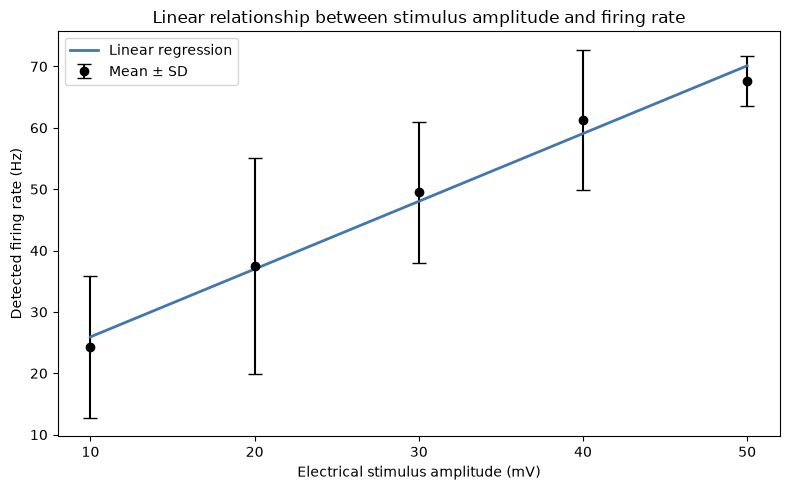

In [24]:
# Plot mean firing rates and linear regression

fig, ax = plt.subplots(figsize=(8, 5))

# Plot mean firing rates with standard deviations
ax.errorbar(
    x, y,
    yerr=summary["SD"].to_numpy(),
    fmt="o",
    color="black",
    capsize=5,
    label="Mean ± SD"
)

# Plot regression line
x_line = np.linspace(10, 50, 100)
y_line = regression.intercept + regression.slope * x_line

ax.plot(
    x_line,
    y_line,
    color="#4477AA",
    linewidth=2,
    label="Linear regression"
)

ax.set_xlabel("Electrical stimulus amplitude (mV)")
ax.set_ylabel("Detected firing rate (Hz)")
ax.set_title("Linear relationship between stimulus amplitude and firing rate")

ax.set_xticks([10, 20, 30, 40, 50])
ax.legend()

plt.tight_layout()
plt.show()

### Statistical analysis: Spike timing

In [ ]:

# Calculate spike phases separately for each recording

def calculate_block_phases(block_index):

    # Extract stimulus and neural signals
    stim = get_channel(0, block_index) * 1000
    neural = get_channel(1, block_index) * 1000

    fs_block = float(mat["samplerate"][0, block_index])

    # Detect candidate action potentials
    baseline = np.median(neural)

    noise = 1.4826 * np.median(
        np.abs(neural - baseline)
    )

    spikes, _ = find_peaks(
        baseline - neural,
        height=6 * noise,
        distance=int(0.002 * fs_block)
    )

    # Identify stimulus peaks
    stim_peaks, _ = find_peaks(
        stim,
        prominence=5,
        distance=int(0.08 * fs_block)
    )

    # Identify the cycle containing each spike
    cycle = np.searchsorted(stim_peaks, spikes) - 1

    valid = (
        (cycle >= 0) &
        (cycle < len(stim_peaks) - 1)
    )

    spikes = spikes[valid]
    cycle = cycle[valid]

    # Calculate phases
    phases = 360 * (
        (spikes - stim_peaks[cycle]) /
        (stim_peaks[cycle + 1] - stim_peaks[cycle])
    )

    return phases


# Store phases separately for each 10-second recording
trial_phases = {}

for amplitude in amplitudes:

    blocks = df.loc[
        df["Stimulus (mV)"] == amplitude,
        "Block"
    ]

    trial_phases[amplitude] = [
        calculate_block_phases(int(b) - 1)
        for b in blocks
    ]

    print(
        f"{amplitude} mV: "
        f"{len(trial_phases[amplitude])} recordings, "
        f"{sum(len(p) for p in trial_phases[amplitude])} spikes"
    )

    # PART 4 - STEP 8B
# Recording-wise phase-shift permutation test

rng = np.random.default_rng(302)

n_permutations = 5000

bins = np.arange(0, 361, 30)


# Measure how strongly spike counts differ
# from an even distribution
def phase_statistic(phases):

    counts, _ = np.histogram(phases, bins=bins)

    expected = counts.sum() / len(counts)

    return np.sum(
        (counts - expected)**2 / expected
    )


results_phase = []

for amplitude in amplitudes:

    recordings = trial_phases[amplitude]

    # Actual phase distribution
    observed_phases = np.concatenate(recordings)

    observed_stat = phase_statistic(observed_phases)

    # Generate randomized distributions
    null_stats = np.zeros(n_permutations)

    for i in range(n_permutations):

        # Randomly rotate each recording's phases
        randomized = [
            (phases + rng.uniform(0, 360)) % 360
            for phases in recordings
        ]

        pooled_randomized = np.concatenate(randomized)

        null_stats[i] = phase_statistic(
            pooled_randomized
        )

    # Calculate permutation p-value
    p_value = (
        np.sum(null_stats >= observed_stat) + 1
    ) / (n_permutations + 1)

    results_phase.append({
        "Amplitude (mV)": amplitude,
        "Observed statistic": observed_stat,
        "Permutation p-value": p_value
    })


phase_stats_df = pd.DataFrame(results_phase)

print(phase_stats_df.round(5))

# Correct for multiple comparisons

# Extract the five permutation p-values
p_values = phase_stats_df["Permutation p-value"].to_numpy()

# Sort p-values from smallest to largest
order = np.argsort(p_values)
sorted_p = p_values[order]

# Apply Holm-Bonferroni correction
n_tests = len(p_values)

adjusted_sorted = np.maximum.accumulate(
    sorted_p * (n_tests - np.arange(n_tests))
)

# Restore original amplitude order
adjusted_p = np.empty_like(p_values)
adjusted_p[order] = np.minimum(adjusted_sorted, 1.0)

# Add corrected p-values to our results
phase_stats_df["Holm-adjusted p"] = adjusted_p

# Identify results below the 0.05 threshold
phase_stats_df["p < 0.05"] = adjusted_p < 0.05

print(phase_stats_df.round(5))

10 mV: 6 recordings, 1438 spikes
20 mV: 6 recordings, 2230 spikes
30 mV: 6 recordings, 2934 spikes
40 mV: 6 recordings, 3651 spikes
50 mV: 6 recordings, 4022 spikes
   Amplitude (mV)  Observed statistic  Permutation p-value
0              10          1739.51321               0.0134
1              20          3251.25561               0.0012
2              30          5689.96728               0.0002
3              40          6214.02219               0.0002
4              50          6706.52511               0.0002
   Amplitude (mV)  Observed statistic  Permutation p-value  Holm-adjusted p  \
0              10          1739.51321               0.0134           0.0134   
1              20          3251.25561               0.0012           0.0024   
2              30          5689.96728               0.0002           0.0010   
3              40          6214.02219               0.0002           0.0010   
4              50          6706.52511               0.0002           0.0010   

   p <